# Del 1: Grundläggande analys och statistik

## Introduktion
Denna analys syftar till att genomföra en grundläggande explorativ dataanalys (EDA) på ett hälsorelaterat dataset (`health_study_dataset.csv`). Målet är att utforska fördelningen av olika hälsomarkörer, identifiera mönster samt undersöka samband mellan livsstils- och biometriska faktorer och förekomsten av sjukdom.

## Datauppsättning & Kolumnbeskrivning
Datasetet innehåller hälsodata för en grupp individer. Nedan följer en beskrivning av datasetets kolumner:

* **`id`**: Unikt identifieringsnummer för varje deltagare.
* **`age`**: Deltagarens ålder (år).
* **`sex`**: Biologiskt kön (`M` = Man, `F` = Kvinna).
* **`height`**: Längd i centimeter (cm).
* **`weight`**: Vikt i kilogram (kg).
* **`systolic_bp`**: Systoliskt blodtryck (mmHg).
* **`cholesterol`**: Kolesterolhalt i blodet (mmol/L).
* **`smoker`**: Rökstatus (`Yes` = Rökare, `No` = Icke-rökare).
* **`disease`**: Förekomst av diagnostiserad sjukdom (`0` = Nej/Frisk, `1` = Ja/Sjukdom).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import sqrt
from scipy import stats

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["figure.dpi"] = 120
np.set_printoptions(precision=3)
pd.set_option("display.precision", 3)

np.random.seed(42)



In [2]:
df = pd.read_csv("../data/health_study_dataset.csv")

print(df.head())
print()
display(df.info())
print(df.describe())


   id  age sex  height  weight  systolic_bp  cholesterol smoker  disease
0   1   57   F   168.9    65.8        141.8         4.58     No        0
1   2   47   M   180.4    95.9        144.8         5.18    Yes        0
2   3   59   F   169.9    82.2        151.7         6.16     No        0
3   4   72   M   157.7    93.1        151.0         6.63     No        0
4   5   46   M   192.6   104.1        144.1         5.21     No        0

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes

None

            id      age   height   weight  systolic_bp  cholesterol  disease
count  800.000  800.000  800.000  800.000      800.000      800.000  800.000
mean   400.500   49.426  171.849   73.413      149.179        4.929    0.059
std    231.084   14.501    9.804   13.685       12.793        0.848    0.235
min      1.000   18.000  144.400   33.700      106.800        2.500    0.000
25%    200.750   39.000  164.775   64.800      140.900        4.328    0.000
50%    400.500   50.000  171.350   73.200      149.400        4.970    0.000
75%    600.250   59.000  178.925   82.600      157.600        5.482    0.000
max    800.000   90.000  200.400  114.400      185.900        7.880    1.000


In [3]:
print(df.isna().sum())          # number of missing values per column
print()
dup_mask = df.duplicated(keep=False)
print("Antal dubletter:", dup_mask.sum())
print()
print(df["sex"].value_counts())
print(df["smoker"].value_counts())  # check that there are only the expected values (M/F, Yes/No)


id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

Antal dubletter: 0

sex
F    403
M    397
Name: count, dtype: int64
smoker
No     587
Yes    213
Name: count, dtype: int64


OBS: Filen (9 kolumner och 800 rader) ser välordnad/rent ut; det finns inga saknade data eller dubbletter. Även datatyperna verkar rimliga.

## Beskrivande analys:

In [4]:
# Beskrivande analys:

cols = ["age", "weight", "height", "systolic_bp", "cholesterol"]
print("- Räkning av medel, median, min och max för: age, weight, height, systolic_bp, cholesterol:\n")
display(df[cols].agg(["mean", "median", "min", "max"]).round(2))


- Räkning av medel, median, min och max för: age, weight, height, systolic_bp, cholesterol:



,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


### Några observationer kring tabellen ovan:
- Medelvärdet och medianen ligger mycket nära varandra för alla fem variabler, vilket tyder på symmetriska fördelningar.

- Minsta värdet för vikt är 33,7 kg, vilket är mycket lågt för en vuxen!! Är detta ett rimligt värde eller ett datafel?!

- Det genomsnittliga systoliska blodtrycket ligger på cirka 149 mmHg, vilket är ganska högt!!.


- Skapa minst 4 olika grafer (t.ex. histogram över blodtryck, boxplot över vikt per kön, stapeldiagram över andelen rökare, & Blodtryck hos rökare jämfört med icke-rökare):


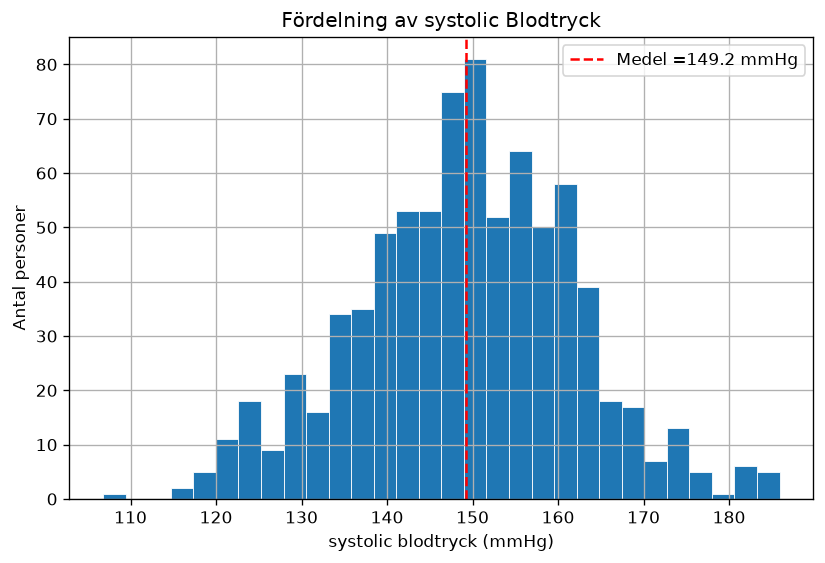

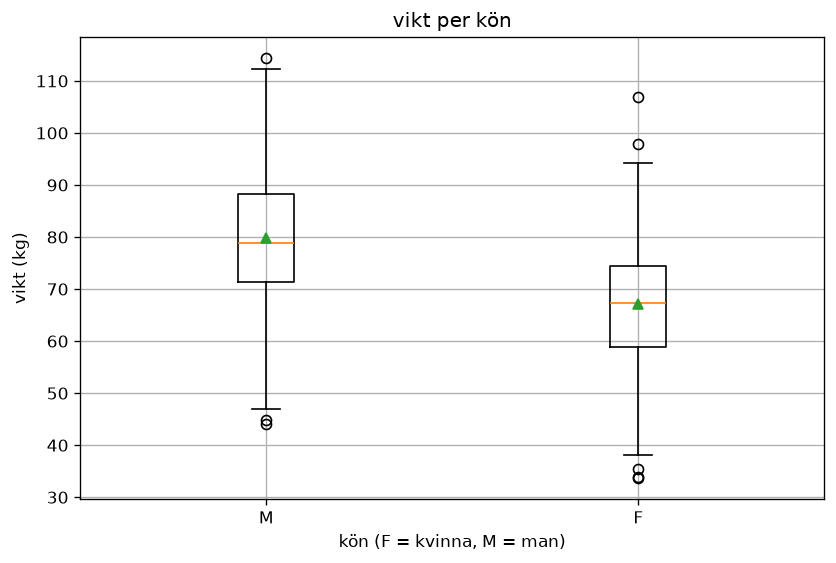

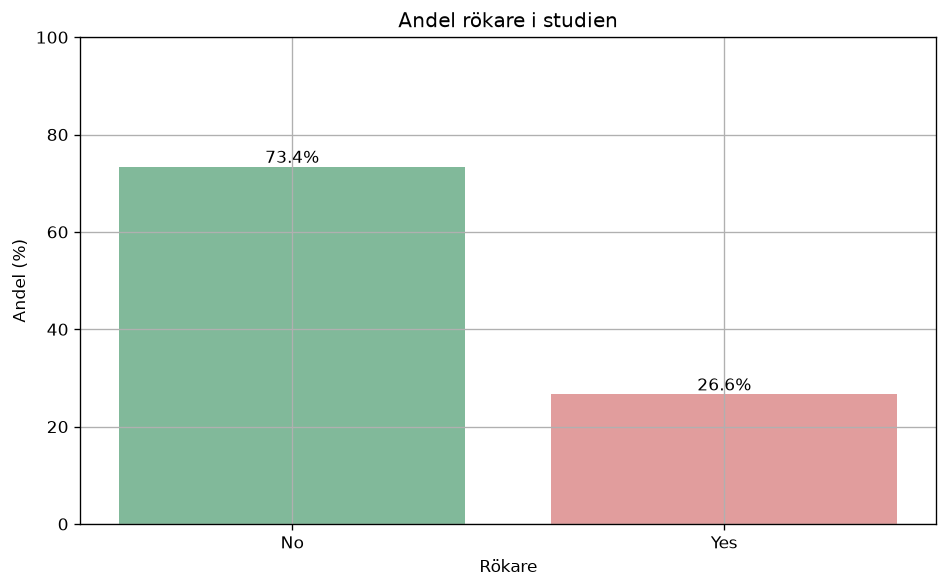

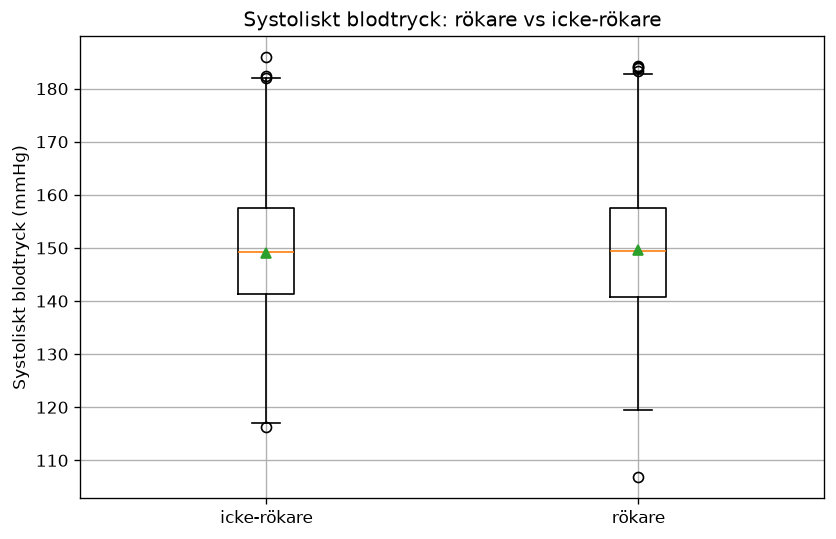

In [5]:
print("\n- Skapa minst 4 olika grafer (t.ex. histogram över blodtryck, boxplot över vikt per kön, stapeldiagram över andelen rökare, & Blodtryck hos rökare jämfört med icke-rökare):")

# graf 1: histogram över blodtryck
fig, ax = plt.subplots()
ax.hist(df["systolic_bp"], bins=30, linewidth=0.5, edgecolor="white")
ax.axvline(df["systolic_bp"].mean(), color="red", linestyle="--", label=f"Medel ={df["systolic_bp"].mean():.1f} mmHg")
ax.set_title("Fördelning av systolic Blodtryck")
ax.set_xlabel("systolic blodtryck (mmHg)")
ax.set_ylabel("Antal personer")
ax.legend()
plt.show()

# graf 2: boxplot över vikt per kön
fig, ax = plt.subplots()
ax.boxplot([df.loc[df.sex == "M", "weight"], df.loc[df.sex == "F", "weight"]], tick_labels=["M", "F"], showmeans=True)
ax.set_title("vikt per kön")
ax.set_xlabel("kön (F = kvinna, M = man)")
ax.set_ylabel("vikt (kg)")
plt.show()

# graf 3:  stapeldiagram över andelen rökare
smoker_share = df["smoker"].value_counts(normalize=True) * 100
fig, ax = plt.subplots()
bars = ax.bar(smoker_share.index, smoker_share.values, alpha=0.6, color=["seagreen", "indianred"])
ax.bar_label(bars, fmt="%.1f%%")
ax.set_title("Andel rökare i studien")
ax.set_xlabel("Rökare")
ax.set_ylabel("Andel (%)")
ax.grid(True, axis="y")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

# graf 4: Blodtryck hos rökare jämfört med icke-rökare
fig, ax = plt.subplots()
ax.boxplot([df.loc[df.smoker == "No", "systolic_bp"], df.loc[df.smoker == "Yes", "systolic_bp"]], tick_labels=["icke-rökare", "rökare"], showmeans=True)
ax.set_title("Systoliskt blodtryck: rökare vs icke-rökare")
ax.set_ylabel("Systoliskt blodtryck (mmHg)")
plt.show()


### observationer från figuror:
- Figur 1: Blodtrycket är ungefär normalfördelat kring medelvärdet ~149 mmHg, med de flesta värden mellan ca 130 och 170 mmHg.
- Figur 2: Männen (M) har högre vikt än kvinnorna (F): medianen är ca 79 kg för män och ca 67 kg för kvinnor, och hela IQR-boxen för män ligger högre. Spridningen är ungefär lika stor i båda grupperna. Det lägsta värdet, 33,7 kg (kvinna), syns som en avvikande punkt och är ovanligt lågt för en vuxen.
- Figur 3: Majoriteten av deltagarna är icke-rökare (73,4 %), medan 26,6 % är rökare.
- Figur 4: Blodtrycket ser ut att vara nästan lika för rökare och icke-rökare. Skillnaden i medelvärde är liten

## Simulering kopplad till caset

In [6]:
# Simulering kopplad till caset

p_disease = df["disease"].mean()
n_disease = df["disease"].sum()

print(f"- Antal sjuka: {n_disease} av {len(df)}  (d.v.s. {p_disease*100:.2f}% av datasetet)")



- Antal sjuka: 47 av 800  (d.v.s. 5.88% av datasetet)


In [7]:
rng = np.random.default_rng(42)                 # creates a random generator with a seed



n_sim = 1000
std_dis = df["disease"].std(ddof=1)          # stickprovsstandardavvikelse
se_dis = std_dis / np.sqrt(n_sim)            # standardfel



n_sim = 1000
sjuk_groups = [0, 1]
simulated = rng.choice(sjuk_groups, size=n_sim, p=[1-p_disease, p_disease])
p_simulated = simulated.mean()

print(f"- Antal sjuka i datasetet    : {n_disease} av {len(df)}  (d.v.s. {p_disease*100:.2f}% av datasetet)")
print(f"- Simulerade sjuka           : {simulated.sum()} av {n_sim} (d.v.s. {p_simulated*100:.2f}% av stickprovet)")
print()
print(f"- Verklig andel              : {p_disease:.4f} ({p_disease*100:.2f} %)")
print(f"- Simulerad andel            : {p_simulated:.4f} ({p_simulated*100:.2f} %)")
print()
print(f"- Förväntad standardavvikelse                    : ±{se_dis*100:.2f} procentenheter")
print(f"- Skillnad mellan simulerade och verkliga andelen: {(p_simulated - p_disease)*100:+.2f} procentenheter")     # :+.2f shows the sign (+ or −) in front of the difference



- Antal sjuka i datasetet    : 47 av 800  (d.v.s. 5.88% av datasetet)
- Simulerade sjuka           : 54 av 1000 (d.v.s. 5.40% av stickprovet)

- Verklig andel              : 0.0587 (5.88 %)
- Simulerad andel            : 0.0540 (5.40 %)

- Förväntad standardavvikelse                    : ±0.74 procentenheter
- Skillnad mellan simulerade och verkliga andelen: -0.47 procentenheter


I datasetet har 47 av 800 deltagare sjukdomen, vilket motsvarar en andel på 5,88 %. När vi simulerar 1000 personer med samma sannolikhet blir 54 sjuka, dvs. en andel på 5,40 %. Skillnaden (−0,47 procentenheter) är mindre än den förväntade slumpvariationen (standardavvikelse ≈ ± 0,74 procentenheter), så den simulerade andelen stämmer väl överens med den verkliga.

## Konfidensintervall för medelvärde av systoliskt blodtryck (båda metoderna, för VG)

In [ ]:
# normalapproximation 

def ci_mean_normal(x, confidence=0.95):
    '''
    95%-CI för medel med normal-approximation:
    medel -+  1.96 * (s / sqrt(n))
    '''
    x = np.asarray(x, dtype=float)
    mean__x = float(np.mean(x))         
    s = float(np.std(x, ddof=1))            # stickprovsstandardavvikelse
    n = len(x)

    z_critical = 1.96
    half_width = z_critical * s / sqrt(n)               # = z * SE
    lo, hi = mean__x - half_width, mean__x + half_width
    return lo, hi, mean__x, s, n

lo, hi, mean__x, s, n = ci_mean_normal(df["systolic_bp"])

print(f"Medelvärde      : {mean__x:.2f} mmHg")
print(f"Standardfel     : {(s / sqrt(n)):.3f}")
print(f"95 % KI (normal): [{lo:.2f}, {hi:.2f}] mmHg")


Medelvärde      : 149.18 mmHg
Standardfel     : 0.452
95 % KI (normal): [148.29, 150.07] mmHg


In [13]:
# bootstrap

def ci_mean_bootstrp(x, B=5000, confidence=0.95):
    x = np.asarray(x, dtype=float)
    n = len(x)
    boot_means = np.empty(B)
    for b in range(B):
        boot_sample = np.random.choice(x, size=n, replace=True)
        boot_means[b] = np.mean(boot_sample)

    alpha = (1 - confidence) / 2      # 2.5:e procentilen och 97.5:e procentilen
    lo, hi = np.percentile(boot_means, [100*alpha, 100*(1 - alpha)])
    return float(lo), float(hi), float(np.mean(x)), np.asarray(boot_means, dtype=float)

blo, bhi, bmean, boot_means = ci_mean_bootstrp(df["systolic_bp"], B=10_000)

print(f"95 % KI (bootstrap): [{blo:.2f}, {bhi:.2f}] mmHg")

95 % KI (bootstrap): [148.30, 150.05] mmHg


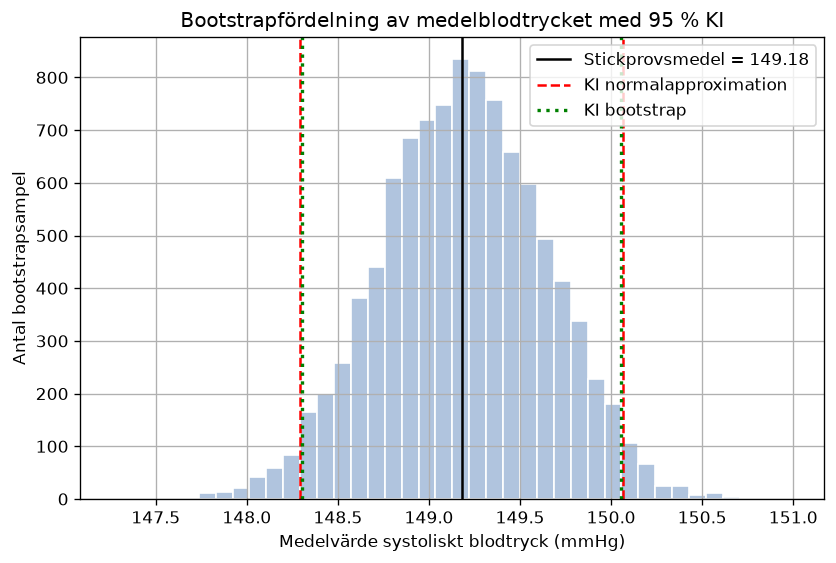

                     Nedre gräns  Övre gräns  Bredd
Normalapproximation       148.29      150.07   1.77
Bootstrap                 148.30      150.05   1.75


In [16]:
fig, ax = plt.subplots()
ax.hist(boot_means, bins=40, color="lightsteelblue", edgecolor="white")

ax.axvline(mean__x, color="black", linestyle="-", label=f"Stickprovsmedel = {mean__x:.2f}")
ax.axvline(lo, color="red", linestyle="--", label="KI normalapproximation")
ax.axvline(hi, color="red", linestyle="--")
ax.axvline(blo, color="green", linestyle=":", linewidth=2, label="KI bootstrap")
ax.axvline(bhi, color="green", linestyle=":", linewidth=2)

ax.set_title("Bootstrapfördelning av medelblodtrycket med 95 % KI")
ax.set_xlabel("Medelvärde systoliskt blodtryck (mmHg)")
ax.set_ylabel("Antal bootstrapsampel")
ax.legend()
plt.show()

comparison = pd.DataFrame({
    "Nedre gräns": [lo, blo],
    "Övre gräns": [hi, bhi],
    "Bredd": [hi - lo, bhi - blo],
}, index=["Normalapproximation", "Bootstrap"]).round(2)

print(comparison)

### Jämförelse av konfidensintervallen

Metoderna stämmer så väl. De två metoderna ger i princip **samma resultat** – gränserna skiljer sig med högst 0,02 mmHg. Vi kan alltså med 95 % säkerhet säga att det sanna medelvärdet för systoliskt blodtryck i populationen ligger mellan ca **148,3 och 150,1 mmHg**.

**blodtrycket är i stort sett symmetriskt fördelat** (se histogrammet ovan), vilket är just den situation där normalapproximationen fungerar bäst. Bootstrapfördelningen i grafen ovan är dessutom klockformad och centrerad kring stickprovsmedelvärdet, vilket bekräftar normalantagandet visuellt.


**Slutsats:** När båda metoderna ger samma intervall stärker det tilliten till resultatet. I det här fallet räcker normalapproximationen, men bootstrap är ett robust alternativ om datan hade varit mindre "snäll".
